## Baseline ML con MLFlow

*Autor: Denisse Martínez Ruiz (A01797970)*

* **Problema**: Predecir el abandono de clientes (churn) de una tienda de comercio electrónico
* **Tipo de problema**: Clasificación binaria (Churn : 1 = el cliente abandona, 0 = el cliente permanece)
* **Dataset**: E - Commerce Customer Churn Analysis and Prediction
* **Fuente**: Kaggle


Contenido:

1. Carga y descripción del dataset
2. Análisis exploratorio (EDA)
3. Limpieza de datos
4. Modelo base
5. Evaluación del modelo
6. Registro del experimento en MLFlow
7. Reflexión sobre MLFLow

### 1. Carga y descripción del dataset

En esta sección se importan los datos, se revisa su estructua  (registros, variables, tipos, etc). 

In [1]:
##Importamos librerías 
import os
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature

SEED = 42

#Configuración de salidas
pd.set_option("display.max_colwidth", None)

/Users/denissemartinez/Documents/Documents - MacBook Air de Denisse/Tecnológico de Monterrey MNA/MLOps/Proyectos/Churn  Reyeslvan/mna_cicd_mlflow_churn/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


#### 1.1 Descarga y carga de datos

Los datos se descargan a través de `kagglehub`, de modo que el notebook se puede reproducir desde cualqueir equipo, evitando dependencia de archivos o rutas locales. 

In [2]:
#Obtenemos los datos y los guardamos en una ruta local
path = kagglehub.dataset_download("ankitverma2010/ecommerce-customer-churn-analysis-and-prediction")

#Imprimimos la ruta del dataset
print("Path to dataset files:", path)

Path to dataset files: /Users/denissemartinez/.cache/kagglehub/datasets/ankitverma2010/ecommerce-customer-churn-analysis-and-prediction/versions/1


In [3]:
#Listamos los archivos sobre la ruta
print(os.listdir(path))

['E Commerce Dataset.xlsx']


In [4]:
#Listamos las hojas disponibles del archivo 
file = os.path.join(path,os.listdir(path)[0] )

excel_file = pd.ExcelFile(file)

print(excel_file.sheet_names)

['Data Dict', 'E Comm']


In [5]:
#Cargamos el dataframe de la data, y el diccionario de datos 
df = pd.read_excel(file, sheet_name = excel_file.sheet_names[1])
data_dict = pd.read_excel(file, sheet_name = excel_file.sheet_names[0])

print(f"Registros: {df.shape[0]} | Variables: {df.shape[1]}")

Registros: 5630 | Variables: 20


### 1.2  Diccionario de datos

La hoja "Data DIct" nos devuelve el significado de cada una de las variales del dataset

In [6]:
data_dict = data_dict.iloc[1: , 2:].copy()
data_dict.columns = ['Variable', 'Descripcion']
data_dict = data_dict.reset_index(drop =True)

In [7]:
data_dict

,Variable,Descripcion
0,CustomerID,Unique customer ID
1,Churn,Churn Flag
2,Tenure,Tenure of customer in organization
3,PreferredLoginDevice,Preferred login device of customer
4,CityTier,City tier
5,WarehouseToHome,Distance in between warehouse to home of customer
6,PreferredPaymentMode,Preferred payment method of customer
7,Gender,Gender of customer
8,HourSpendOnApp,Number of hours spend on mobile application or website
9,NumberOfDeviceRegistered,Total number of deceives is registered on particular customer


#### 1.3 Estructura del dataset
Se revisan los tipos de datos y la cantidad de valores faltantes por variable.

In [8]:
#Información sobre el tipo de datos y valores nulos
df.info()

#Valores faltante por variable
nulls = df.isnull().sum()
nulls_resume = pd.DataFrame({
    "Nulos": nulls,
    "Porcentaje": (nulls / len(df)* 100).round(2)
})
nulls_resume.sort_values(by="Porcentaje", ascending=False).head(8)

<class 'pandas.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5630 non-null   int64  
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   str    
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMode         5630 non-null   str    
 7   Gender                       5630 non-null   str    
 8   HourSpendOnApp               5375 non-null   float64
 9   NumberOfDeviceRegistered     5630 non-null   int64  
 10  PreferedOrderCat             5630 non-null   str    
 11  SatisfactionScore            5630 non-null   int64  
 12  MaritalStatus                5630 non-null   str    
 13  NumberOfAddress              

,Nulos,Porcentaje
DaySinceLastOrder,307,5.45
OrderAmountHikeFromlastYear,265,4.71
Tenure,264,4.69
OrderCount,258,4.58
CouponUsed,256,4.55
HourSpendOnApp,255,4.53
WarehouseToHome,251,4.46
CustomerID,0,0.00


In [9]:
df.head()

,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


#### 1.4 Descripción de las variables 

El dataset contiene 5630 registros y 20 variables  (7 enteras, 8 decimales y 5 de texto)

| Variable  | Tipo  | Significado   |
| --- | --- | --- |
|`CustomerID` | Identificador | Identificador único del cliente |
|`Churn` | Objetivo | 1 si el cliente abandona, 0 si continua  |
|`Tenure`  | Numérica | Antiguedad del cliente en la tienda (No se menciona si se mide en meses, años, etc)|
|`PreferedLoginDevice`| Categórica | Dispositivo preferido para iniciar sesión |
|`CityTier` | Categórica ordinal | Nivel de la cidudad donde vive el cliente |
|`WarehouseToHome` | Numérica | Distancia entre el almacen y el domicilio del cliente |
|`PreferredPaymentMode`| Categórica | Método de pago preferido |
|`Gender`| Categórica | Genero del cliente |
|`HourSpendOnApp`| Numérica | Horas que el cliente pasa en la aplicación o sitio web|
|`NumberOfDeviceRegistered`| Numérica | Numero de dispositivos registrados |
|`PreferedOrderCat`| Categórica | Categoría de producto preferido en el último mes| 
|`SatisfactionScore`| Ordinal | Calificación de satisfacción del serivicio|
|`MaritalStatus`| Categórical | Estado civil|
|`NumberOfAddress` | Numérica | Número de direcciones agregadas por cliente|
|`Complain` | Binaria  | Si el cliente presentó una queja el último mes |
|`OrderAmountHikeFromlastYear`| Numérica | Aumento en monto de peddos en comparación con el último año (%)|
|`CouponUsed`| Numérica | Numero de cupones utilizados el último mes |
|`OrderCount `| Numérica | Número de pedidos el último mes |
|`DaySinceLastOrder `| Numérica | Número de días transcurridos desde el ultimo pedido|
|`CashbackAmount`| Numérica | Promedio de cashback el último mes |


--Notas--:

* Siete variables tienen entre 250 y 307 valores faltantes, un promedio del 5% del total
* CustomerID es un indentificador y se excluira del modelo
* CityTier es una categoria guardada como numérica
* PreferredLoginDevice pareciera tener categorias repetidas


## 2. Análisis exploratorio de datos

In [10]:
#Definimos las variables numéricas y categóricas 

num_cols = [ "Tenure", "WarehouseToHome", "HourSpendOnApp",
    "OrderAmountHikeFromlastYear", "CouponUsed", "OrderCount",
    "DaySinceLastOrder", "CashbackAmount",
    "NumberOfDeviceRegistered", "NumberOfAddress",]
cat_cols = ["PreferredLoginDevice", "PreferredPaymentMode", "Gender",
    "PreferedOrderCat", "MaritalStatus", "CityTier",
    "SatisfactionScore", "Complain",]

### 2.1 Estadísticas descriptivas
Resumen de las variables numéricas (media, moda, mediana, quartiles, desviación), y se revisan las categóricas (categorias, frecuencia )

In [11]:
#Aplicamos describe únciamente a las columnas numéricas
display(df[num_cols].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Tenure,5366.0,10.19,8.56,0.0,2.00,9.00,16.00,61.00
WarehouseToHome,5379.0,15.64,8.53,5.0,9.00,14.00,20.00,127.00
HourSpendOnApp,5375.0,2.93,0.72,0.0,2.00,3.00,3.00,5.00
OrderAmountHikeFromlastYear,5365.0,15.71,3.68,11.0,13.00,15.00,18.00,26.00
CouponUsed,5374.0,1.75,1.89,0.0,1.00,1.00,2.00,16.00
OrderCount,5372.0,3.01,2.94,1.0,1.00,2.00,3.00,16.00
DaySinceLastOrder,5323.0,4.54,3.65,0.0,2.00,3.00,7.00,46.00
CashbackAmount,5630.0,177.22,49.21,0.0,145.77,163.28,196.39,324.99
NumberOfDeviceRegistered,5630.0,3.69,1.02,1.0,3.00,4.00,4.00,6.00
NumberOfAddress,5630.0,4.21,2.58,1.0,2.00,3.00,6.00,22.00


In [12]:
#Con value_counts obtenemos las categorías de las variables
for cat in cat_cols:
    print(f"{'='*10}{cat}{'='*10}")
    print(df[cat].value_counts(dropna=False))

==========PreferredLoginDevice==========
PreferredLoginDevice
Mobile Phone    2765
Computer        1634
Phone           1231
Name: count, dtype: int64
==========PreferredPaymentMode==========
PreferredPaymentMode
Debit Card          2314
Credit Card         1501
E wallet             614
UPI                  414
COD                  365
CC                   273
Cash on Delivery     149
Name: count, dtype: int64
==========Gender==========
Gender
Male      3384
Female    2246
Name: count, dtype: int64
==========PreferedOrderCat==========
PreferedOrderCat
Laptop & Accessory    2050
Mobile Phone          1271
Fashion                826
Mobile                 809
Grocery                410
Others                 264
Name: count, dtype: int64
==========MaritalStatus==========
MaritalStatus
Married     2986
Single      1796
Divorced     848
Name: count, dtype: int64
==========CityTier==========
CityTier
1    3666
3    1722
2     242
Name: count, dtype: int64
==========SatisfactionScore========

* **Tamaño de la muetra**: Observamos que aquellas variables con una muestra menor al total, coincide con aquellas que identificamos previsamente con valores nulos.
+ **Outliers**: Existen varias columnas donde parecieran existir outliers, el valor máximo es por mucho más alto del percentil 75

    * *Tenure*: Teniendo un máximo de 61, mientras que en su percentil 75 es de 18
    * *WarehouseToHome*: En su percentil 75 vemos un valor de 20, mientras que en su máximo vemos 127, 
    * *DaySinceLastOrder*: Vemos en su percentil 75 un valor de 7, por otro lado en su máximo alcanza los 46.
    * *NumberOfAddress*: Con 33 en su percetil 75 yb un valor máximo de 6.

* **Asimétricas**: Se presenta asimetría cuando la distribución de una variable no es simétrica. Una diferencia entre la media y la mediana puede ayudar a identificarla: cuando la media es mayor que la mediana, podría indicar un sesgo a la derecha (positivo), mientras que si es menor, podría indicar un sesgo a la izquierda (negativo). Este comportamiento se observa en las variables *Tenure*, *CouponUsed* y *OrderCount*, donde sus medias son mayores que sus medianas, lo que podría significar un posible sesgo a la dereha.
* **Valores con 0**: En el caso de las variables *Tenure*, *HourSpendOnApp**, *CouponUsed*, *DaySinceLastOrder* y *CashbackAmount* son valores donde el min es igual a 0, esto no quiere decir que sea incorrecto, pero a partir del contexto de cada una podemo identificar si un registro podría considerarse como vacio aún teniendo 0.
* **Categorias duplicadas**: 

    * *PreferredLoginDevice*: Muestra dos categorias que podrían significar lo mismo *Mobile* Y *MobilePhone*
    * *PreferredPaymentMode*: Muestra 4 variables que podrían estar repetidas *Credit Card* con *CC* y *Cash on Delivery* con *COD*
    * *PreferedOrderCat*: Mismo caso que *PreferredLoginDevice*

### 2.2 Distribución de la variable ojetivo

Se revisa la distribución de la variable objetivo, si existe algún desbalanceo de clases.

In [13]:
#Obtenemos el número de clientes de cada clase
count = df["Churn"].value_counts()
#Obtenemos el porcentaje de cada clase
porcentaje = df["Churn"].value_counts(normalize=True)*100
#Generamos el df de resumen de la distribución de clases
resume = pd.DataFrame({
        "Clientes": count,
        "Porcentaje": porcentaje
    }
)
resume

,Clientes,Porcentaje
Churn,,
0,4682,83.161634
1,948,16.838366


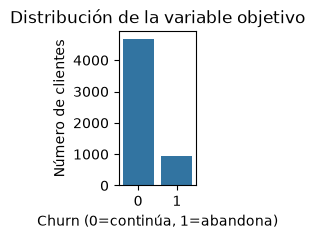

In [14]:
#Grafico de barras
fig, ax = plt.subplots(figsize=(1, 2))
ax = sns.countplot(data=df, x="Churn")
ax.set_title("Distribución de la variable objetivo")
ax.set_xlabel("Churn (0=continúa, 1=abandona)")
ax.set_ylabel("Número de clientes")

plt.show()

De los 5630 cientes, **4682 (83.2%)** son clientes que permaneces, por otro lado, *948 (16.8%)* son clientes que avandonan la compañia. Se observa cierto desbalance en las clases lo cual podría afectar las predicciones y se tiene que tomar en cuenta ya que el modelo podría aprender de la clases que no abandona al ser la que más aparece y daría como consecuencia un accuracy alto sin que esto realmente signifique que esta aprendiendo relamente. 

De cara en las métricas seleccionadas no podemos considerar solo accuracy, tenemos que considerar métricas como `recall`, `F1`, `precision`, `ROC-AUC`. Además que una `división estratificada` de los datos. 

#### 2.3 Distribución de las varibales numéricas 
Observamos la distribución de las variables numéricas en busqueda de sesgos, y presencia de outliers

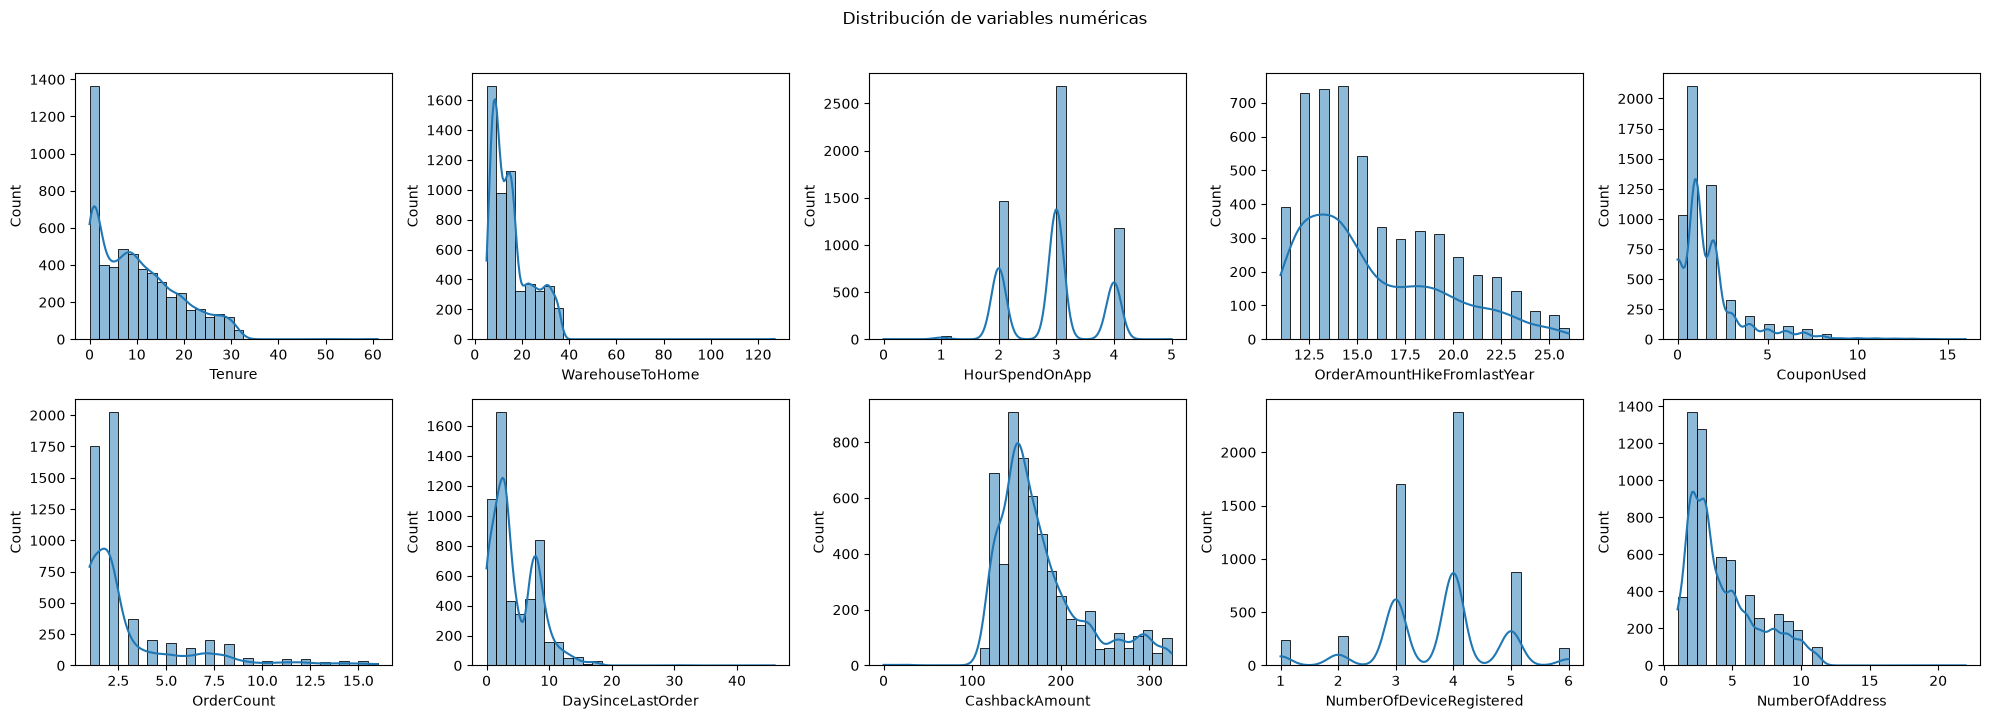

In [15]:
#Histograas con seaborn para las variables numéricas
fig, axes = plt.subplots(2, 5, figsize=(20,7))
for ax, col in zip(axes.flatten(), num_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=ax)
    ax.set_title = col
    
plt.suptitle("Distribución de variables numéricas", y=1.02)
plt.tight_layout()
plt.show()

Aqui confirmamos algunos puntos mencionados previamente. 

* **Sesgadas a la derecha:** `Tenure`, `WarehouseToHome`, `CouponUsed`, `OrderCount`, `DaySinceLastOrder`, `CashbackAmount` y `NumberOfAddress`. La mayoría de los clientes tiene valores bajos y una minoría tiene valores muy altos.
* **`Tenure`** Tiene un pico cerca de 0, lo que podría significar que la mayoria de los clientes son muy recientes.
* **`CouponUsed` y `OrderCount`** se concentran en 1 y 2, con una cola larga hasta 16, lo que representa que la gran mayoria de clientes ha realizado pocos pedidos y muy pocos de ellos ha echo uso de algún cupon. 
* **Variables casi discretas:** `HourSpendOnApp` toma básicamente los valores 2, 3 y 4 (con 3 como el más común), y `NumberOfDeviceRegistered` se concentra en 3, 4 y 5. Se tratan como numéricas, pero no son continuas.
* **`WarehouseToHome` y `DaySinceLastOrder`** confimamos lo que visualizamos con el análisis descriptivo, la presencia de **outliers**
* **`CashbackAmount`** se concentra alrededor de 150 y tiene una cola hacia valores altos (hasta ≈325).

### Varibales categóricas
Frecuencia de las categorias mediante gráficas, se buscan aquellas que predominan

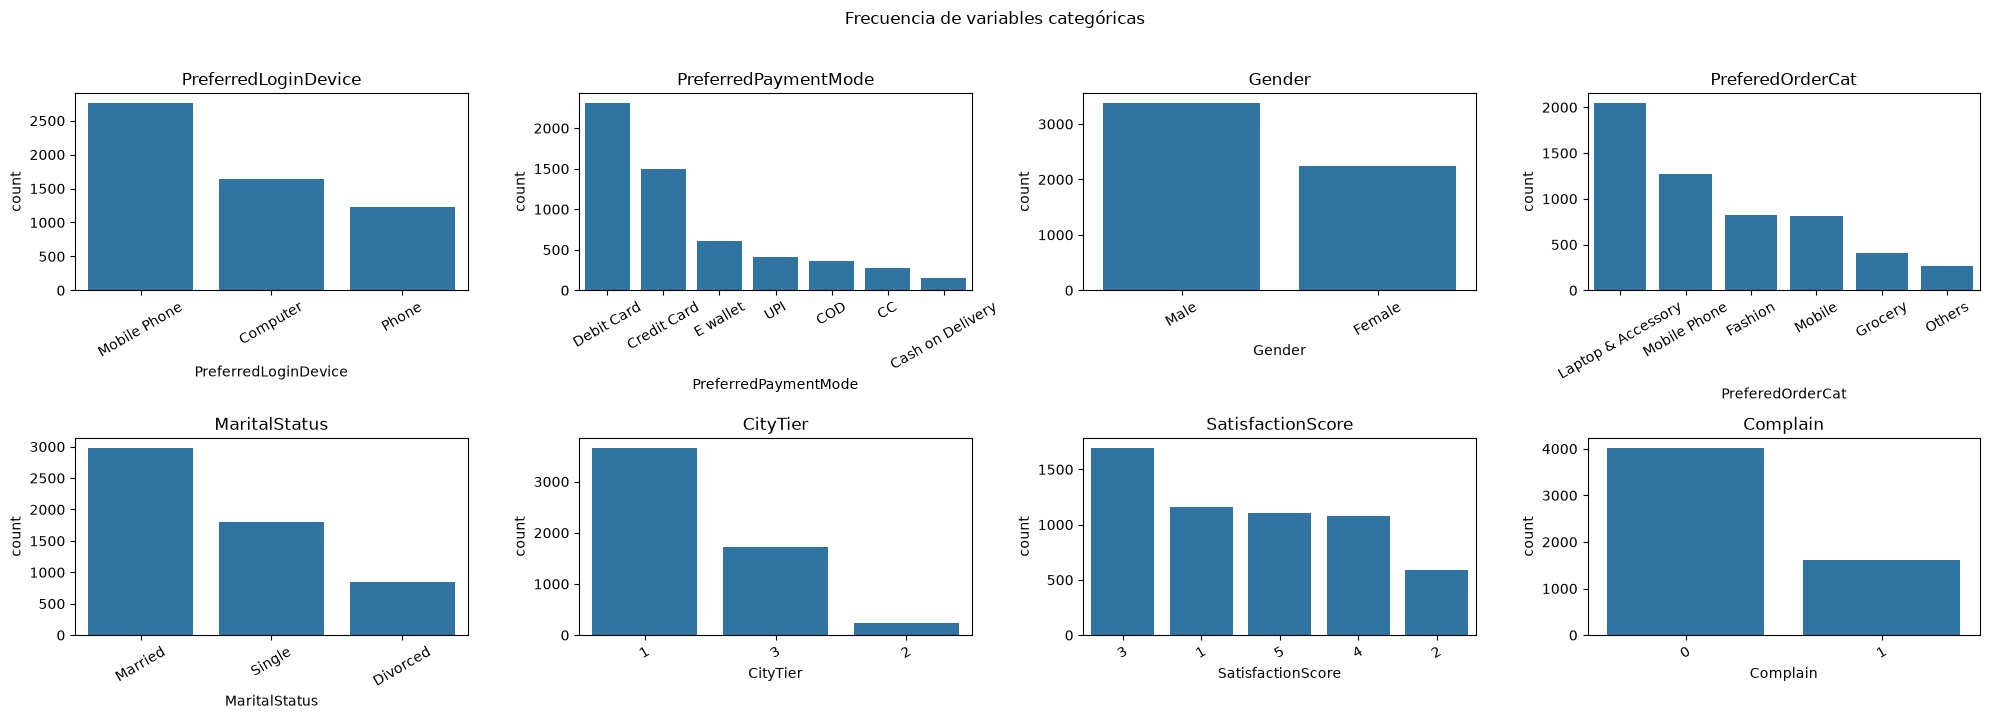

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(20,7))
for ax, col in zip(axes.flatten(), cat_cols):
    categories = df[col].value_counts().index
    sns.countplot(data=df, x= col, order= categories, ax= ax)
    ax.set_title(col)
    ax.tick_params(axis = "x", rotation=30)
plt.suptitle("Frecuencia de variables categóricas", y=1.02)
plt.tight_layout()
plt.show()

* **Duplicados confirmados.** Las gráficas muestran por separado "Mobile Phone" y "Phone" (`PreferredLoginDevice`), "Credit Card" y "CC", "Cash on Delivery" y "COD" (`PreferredPaymentMode`), y "Mobile Phone" y "Mobile" (`PreferedOrderCat`). Son etiquetas distintas para posibles categorías iguales y posteriormente las unificaremos.
* **Desbalance entre categorías.** `CityTier` predomina el nivel 1 (3,650 clientes) y el nivel 2 tiene muy pocos (240). `Gender` tiene más hombres que mujeres. `MaritalStatus` tiene en su gran mayoria casados.
* **Perfil general.** Los clientes prefieren pagar con tarjeta de débito, entran sobre todo desde el celular y compran sobre todo "Laptop & Accessory".
* **Quejas.** Aproximadamente una cuarta parte presentó una queja en el último mes.

### 2.5 Relación de las variables con la variable objetivo

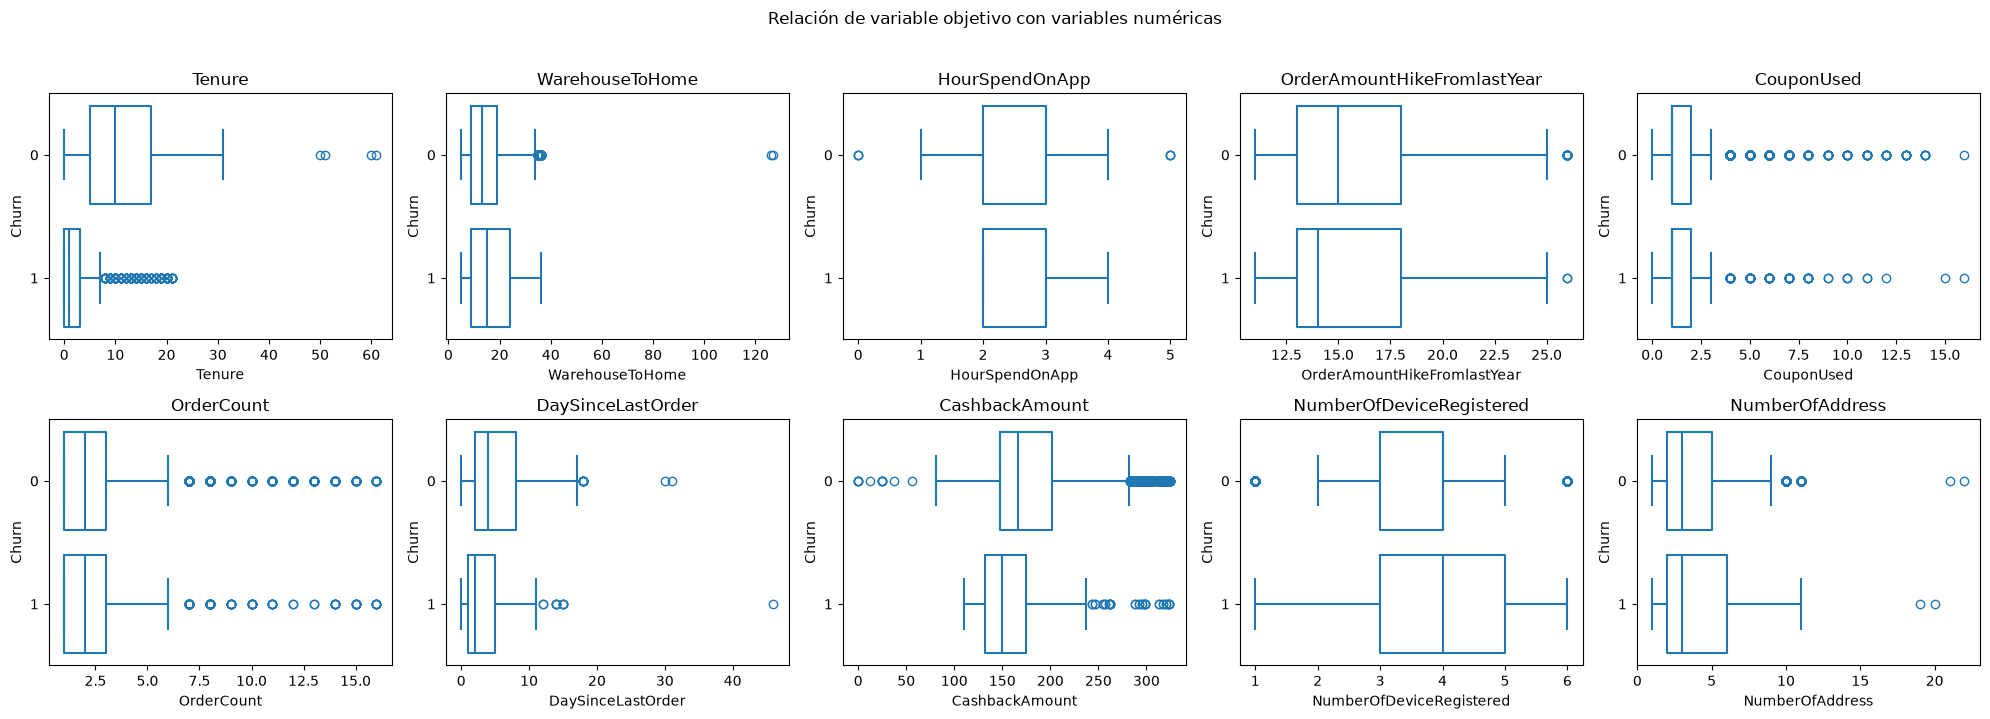

In [17]:
fig, axes = plt.subplots(2, 5, figsize=(20,7))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(data=df, x=col, y="Churn", fill=False, ax=ax, orient="h")
    ax.set_title(col)
    ax.set_ylabel("Churn")

plt.suptitle("Relación de variable objetivo con variables numéricas", y=1.02)
plt.tight_layout()
plt.show()


* **`Tenure` es la variable que más diferencía a las dos clases.** Los clientes que abandonan son los que menor antiguedad tienen. 
* **`DaySinceLastOrder` y `CashbackAmount`** tienden a ser más bajos en quienes abandonan, lo que podria traducirse a que compraron recientemente pero recibieron menos cashback.
* **`NumberOfDeviceRegistered` y `NumberOfAddress`** Los clientes que abandonan tiene a registrar por un poco más dispositivos y direcciones en comparación de los que no.
* **`HourSpendOnApp`, `OrderAmountHikeFromlastYear`, `CouponUsed` y `OrderCount`** casi no muestran diferencias entre ambos grupos.
* **Valores extremos aislados.** Destacan `WarehouseToHome ≈ 127`, `DaySinceLastOrder ≈ 46` y `NumberOfAddress ≈ 22`. A diferencia de los puntos de `CouponUsed`, `OrderCount` o `CashbackAmount`, que forman colas continuas posiblemente sea un comportamiento real


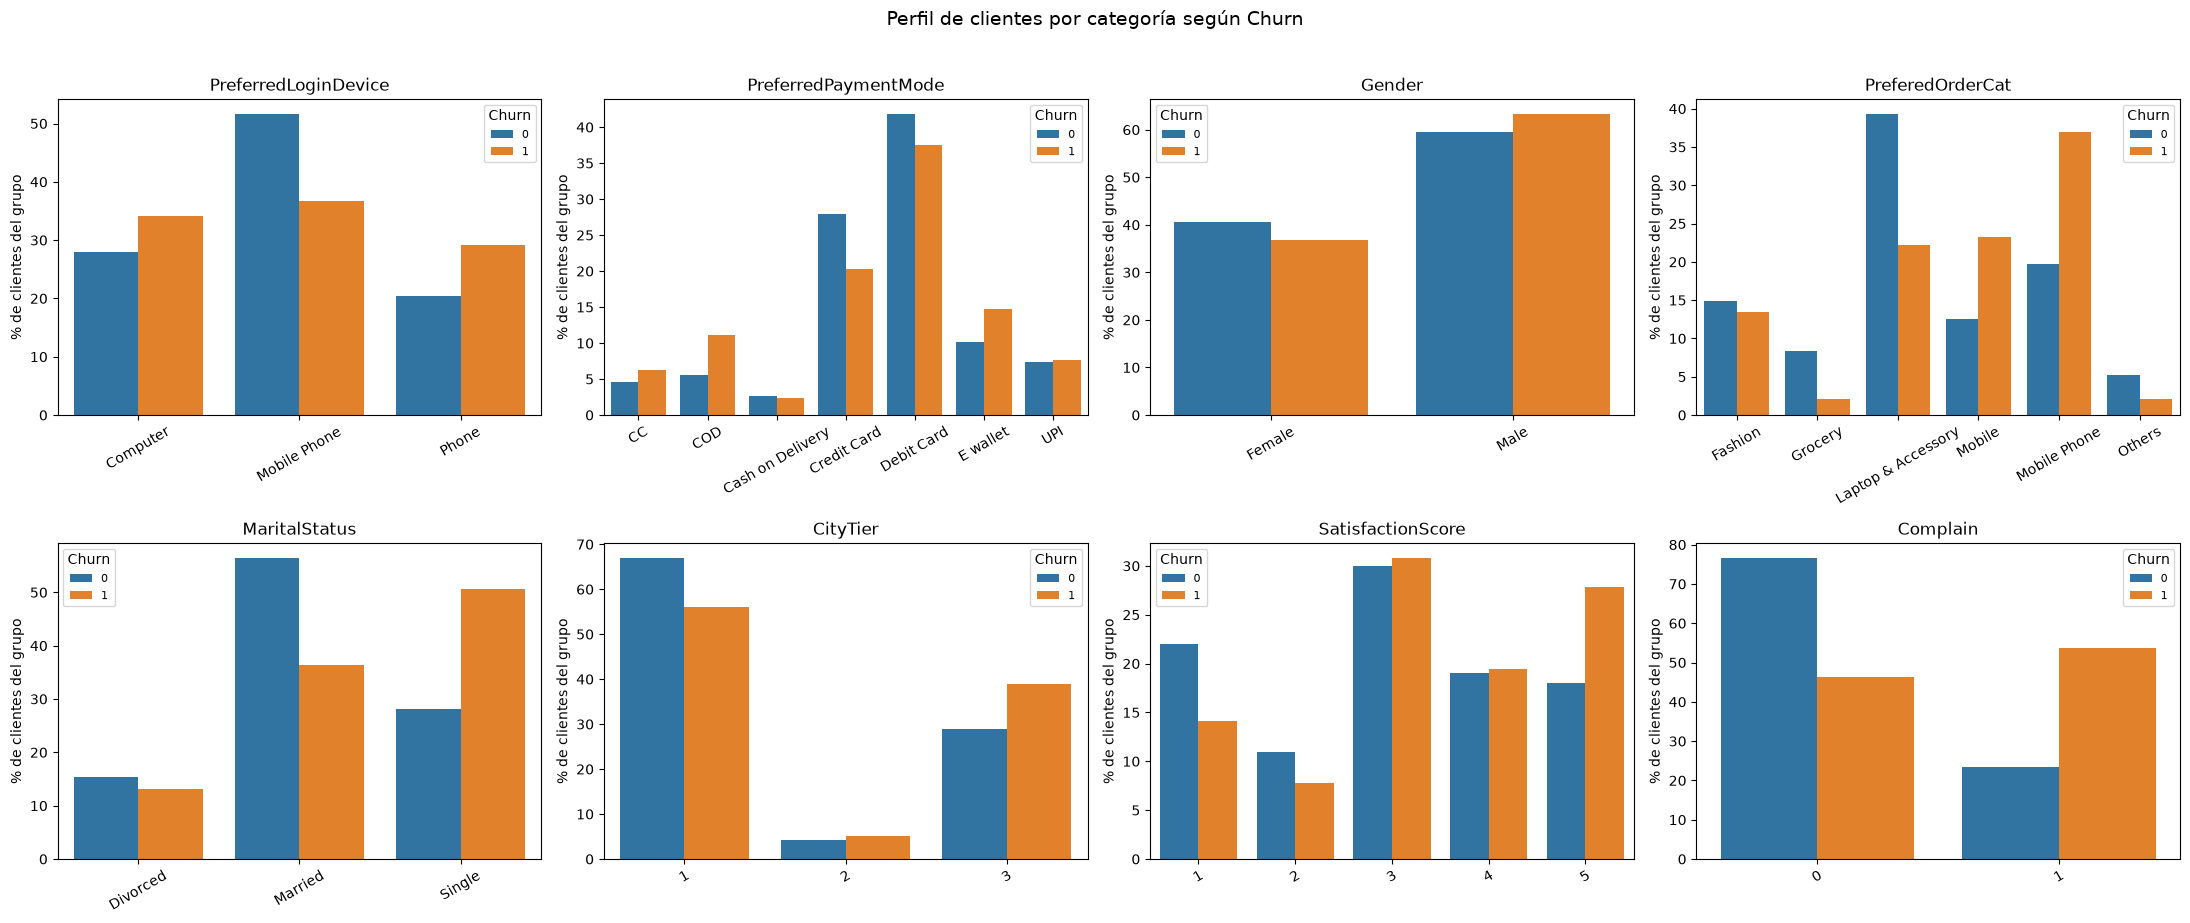

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(22, 9))

for ax, col in zip(axes.flatten(), cat_cols):
    # % de cada categoría dentro de cada grupo de Churn
    cat = (
        pd.crosstab(df[col], df["Churn"], normalize="columns")
        .mul(100)
        .reset_index()
        .melt(id_vars=col, var_name="Churn", value_name="% de clientes")
    )
    cat[col] = cat[col].astype(str)

    sns.barplot(data=cat, x=col, y="% de clientes", hue="Churn", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("% de clientes del grupo")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(title="Churn", fontsize=8)

plt.suptitle("Perfil de clientes por categoría según Churn", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

Las barras color azul corresponden a los clientes que permanecen y naranja a quienes abandonan. Así podemos comparar qué categorías tienen mayor presencia en cada grupo.

* **`Complain`:** Poco más del 50% de quienes abandonan presentó una queja, en comparación con el 25% de quienes permanecen.
* **`MaritalStatus`:** Son más la cantidad de solteros que tieden a abandonar, por otro lado los casados son aquellos que permanecen.
* **`PreferedOrderCat`:** Mobile Phone y Mobile son categorias de compra de quienes tienden a abondanar la caompañia, mientras que Laptop & Accessory son las categorias preferidas de aquellos clientes que permanecem.
* **`CityTier`:** el nivel 3 tiene mayor peso entre quienes abandonan, mientras que el nivel 1 predomina entre quienes permanecen.
* **`PreferredPaymentMode`:** COD y E wallet son los metodos preferidos de pago de aquellos que abandonan, mientras que "Credit Card" suele ser el favorito de quienes permanecen.

**Diferencias pequeñas:** `Gender`, `UPI`, `Cash on Delivery`, `Fashion`, `Divorced` y los puntajes de satisfacción 3 y 4 muestran diferencias poco marcadas entre ambos grupos.

**Hallazgos para la limpieza:** algunas categorías que parecen duplicadas presentan comportamientos distintos, como `CC` y `Credit Card`, o `COD` y `Cash on Delivery`. Por ello, conviene revisar si realmente representan lo mismo antes de unificarlas. Identificamos que los puntajes de satisfacción 1 y 2 son menos seleccionados por las personas que abandonan, mientras que el puntaje 5 es el que más se selecciona. Este comportamineto no corresponde a lo que se esperaría, por lo que podría significar una mala interpretación del score.


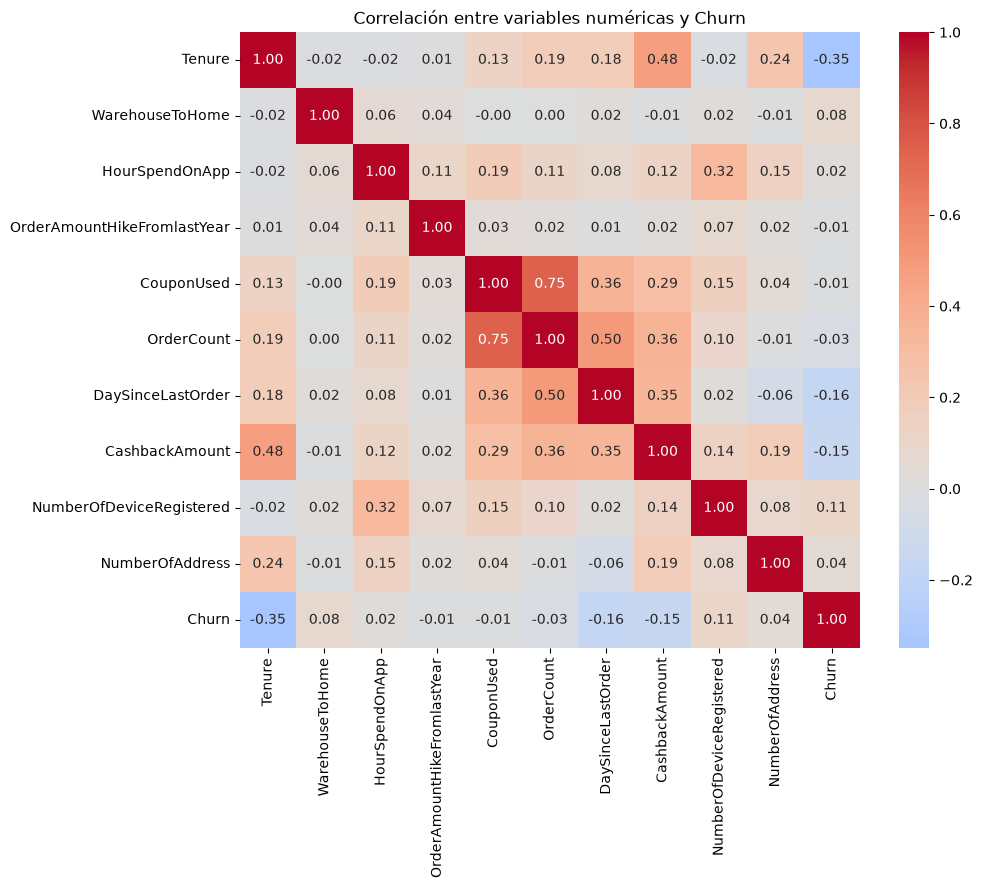

Tenure                        -0.349
DaySinceLastOrder             -0.161
CashbackAmount                -0.154
NumberOfDeviceRegistered       0.108
WarehouseToHome                0.077
NumberOfAddress                0.044
OrderCount                    -0.029
HourSpendOnApp                 0.019
OrderAmountHikeFromlastYear   -0.010
CouponUsed                    -0.008
Name: Churn, dtype: float64

In [19]:
# Matriz de correlación entre variables numéricas y Churn
corr = df[num_cols + ["Churn"]].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlación entre variables numéricas y Churn")
plt.show()

# Correlación de cada variable con Churn, ordenada
corr["Churn"].drop("Churn").sort_values(key=abs, ascending=False).round(3)

* **Relación con Churn.** La correlación más fuerte es con `Tenure` (**-0.35**), a mayor antigüedad, menos abandono. Le siguen `DaySinceLastOrder` (−0.16), `CashbackAmount` (−0.15) y `NumberOfDeviceRegistered` (+0.11). 
* **Colinealidad entre variables explicativas.** `CouponUsed` y `OrderCount` están muy correlacionadas (**0.75**), lo que podría significar que los clientes que realizan más pedidos podrían hacer hecho uso de más cupones. También hay relación moderada entre `Tenure` y `CashbackAmount` (0.48), aquellos clientes con mayor antiguedad son aquellos que recibieron mayor cashback y entre `OrderCount` y `DaySinceLastOrder` (0.50) donde los clientes con mayor numero de ordenes son los que probablememente no han realizado pedidos recientemente. Esto importa para el modelo base porque regresión logística es sensible a la colinealidad.

### 2.6 Detección de valores atípicos

In [20]:
filas=[]
for col in num_cols:
    serie = df[col].dropna()
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (serie < lim_inf) | (serie > lim_sup)
    filas.append({
        "Variable": col,
        "Q1": q1, "Q3": q3,
        "Límite inf.": lim_inf, "Límite sup.": lim_sup,
        "N atípicos": int(mask.sum()),
        "% atípicos": round(mask.mean() * 100, 2),
        "Mín. observado": serie.min(),
        "Máx. observado": serie.max(),
    })
display(pd.DataFrame(filas).set_index("Variable"))

,Q1,Q3,Límite inf.,Límite sup.,N atípicos,% atípicos,Mín. observado,Máx. observado
Variable,,,,,,,,
Tenure,2.00,16.0000,-19.00000,37.00000,4,0.07,0.0,61.00
WarehouseToHome,9.00,20.0000,-7.50000,36.50000,2,0.04,5.0,127.00
HourSpendOnApp,2.00,3.0000,0.50000,4.50000,6,0.11,0.0,5.00
OrderAmountHikeFromlastYear,13.00,18.0000,5.50000,25.50000,33,0.62,11.0,26.00
CouponUsed,1.00,2.0000,-0.50000,3.50000,629,11.70,0.0,16.00
OrderCount,1.00,3.0000,-2.00000,6.00000,703,13.09,1.0,16.00
DaySinceLastOrder,2.00,7.0000,-5.50000,14.50000,62,1.16,0.0,46.00
CashbackAmount,145.77,196.3925,69.83625,272.32625,438,7.78,0.0,324.99
NumberOfDeviceRegistered,3.00,4.0000,1.50000,5.50000,397,7.05,1.0,6.00


Para identificar posibles valores atípicos, utilizamos el rango intercuartílico (IQR), que permite detectar los valores que quedan por debajo del límite inferior o por encima del límite superior. Sin embargo, que un valor quede fuera de estos límites no significa necesariamente que sea un error. Por ello, agrupamos los resultados en tres categorías según qué tan alejados están del resto de los datos y si su valor parece razonable.

**1. Pocos registros con valores muy alejados del resto, que conviene revisar.**

* `WarehouseToHome`: Se identificaron 2 registros (0.04%) con valores de hasta 127, cuando el límite superior es 36.5 y la mayoría de los datos se concentra por debajo de 36. Es el caso que genera mayor sospecha de un posible error de captura, ya que los valores encontrados son aproximadamente tres veces mayores que el límite identificado.

* `Tenure`: Hay 4 registros (0.07%) con valores de 50, 51, 60 y 61, mientras que el resto de los datos llega hasta 31. Aunque están bastante alejados del resto, corresponden a clientes que permanecen activos y donde las demás variables presentan valores normales. Ppodrían representar clientes con mayor antigüedad y no necesariamente errores.

* `NumberOfAddress`: Se encontraron 4 registros (0.07%) con entre 19 y 22 direcciones, por encima del límite superior de 12. Son casos poco comunes que vale la pena revisar, aunque no se puede descartar que sean válidos.

* `DaySinceLastOrder`: Se identificaron 62 registros (1.16%) por encima de 14.5 días. En general, los valores siguen una tendencia gradual que podría corresponder a clientes que llevan más tiempo sin realizar pedidos. Sin embargo, el valor máximo de 46 días destaca por estar más alejado del resto y podría revisarse con mayor detalle.

**2. Valores identificados por el IQR que no necesariamente representan un problema.**

* `HourSpendOnApp` y `NumberOfDeviceRegistered`: Se marcaron 6 y 397 registros (7.05%), respectivamente. En ambas variables, el IQR es de apenas una unidad, por lo que pequeñas diferencias hacen que algunos valores queden fuera de los límites. Sin embargo, los valores identificados, como 0 y 5 horas o entre 1 y 6 dispositivos.

* `OrderAmountHikeFromlastYear`: Se encontraron 33 registros (0.62%) con un valor de 26, una diferencia muy pequeña en comparación con el límite superior de 25.5. Debido a que la diferencia es mínima y el valor se encuentra dentro del rango esperado de la variable, no parece necesario tratar estos registros como errores.

**3. Variables con muchos valores marcados debido a una distribución de cola larga.**

* `CouponUsed` y `OrderCount`: Se identificaron 629 registros (11.7%) y 703 registros (13.1%), respectivamente. Como el IQR es de solo una unidad para `CouponUsed` y dos para `OrderCount`, el método marca como atípicos a los clientes que utilizan 4 o más cupones o realizan 7 o más pedidos. Sin embargo, ambas variables presentan una cola larga, con valores de hasta 16, lo que puede reflejar diferencias reales en el comportamiento de los clientes. 

* `CashbackAmount`: Se marcaron 438 registros (7.8%), con valores de hasta aproximadamente 325. La variable también presenta una cola larga y está relacionada con la antigüedad y la cantidad de pedidos, por lo que estos valores podrían representar a clientes con mayor actividad o consumo, en lugar de errores.


Finalmente observamos que no todos los valores identificados mediante el IQR deben tratarse como errores. Los casos que requieren mayor atención son los del primer grupo, especialmente `WarehouseToHome`, cuyo valor máximo de 127 resulta considerablemente alejado del resto. En las demás variables podría ser parte de su comportamiento o a las características de su distribución. 


### Conclusiones del EDA

**1. Distribución de la variable objetivo**

La mayoría de los clientes permanece con un total de 4,682 (83.2%), mientras que 948 (16.8%) abandonan. Como los grupos no están equilibrados, dividiremos los datos de forma estratificada para conservar sus proporciones. Además, evaluaremos el modelo con métricas como *recall*, *precision*, *F1* y *ROC-AUC*, y no únicamente con *accuracy*.

**2. ¿Qué distingue a los clientes que abandonan?**

* **Antigüedad (`Tenure`):** es la variable que muestra la relación más clara con el abandono (correlación de −0.35). Quienes abandonan suelen tener valores pequeños en esta variable representando menor antigüedad, mientras que entre quienes permanecen la mediana es de aproximadamente 10. Esta diferencia se mantiene en las distintas categorías analizadas.
* **Quejas (`Complain`):** alrededor del 53% de quienes abandonan presentó una queja, frente al 23% de quienes permanecen. Es una de las diferencias más marcadas entre ambos grupos.
* **Perfil del cliente:** los solteros, los clientes de ciudades de nivel 3, quienes pagan con COD o e-wallet y quienes prefieren las categorías "Mobile" y "Mobile Phone" tienen mayor presencia entre quienes abandonan. En cambio, "Laptop & Accessory", "Grocery" y "Others" son preferidas por quienes permanecen.
* **Otras variables numéricas:** `DaySinceLastOrder` (−0.16), `CashbackAmount` (−0.15) y `NumberOfDeviceRegistered` (+0.11) presentan relaciones débiles con el abandono. Variables como `HourSpendOnApp`, `OrderAmountHikeFromlastYear`, `CouponUsed` y `OrderCount` muestran poca diferencia entre los grupos.
* **Variables con poca diferencia:** `Gender` y categorías como UPI, "Cash on Delivery", "Fashion", "Divorced" y los puntajes de satisfacción 3 y 4 aportan pocas diferencias visibles entre quienes permanecen y quienes abandonan.
* **Satisfacción:** los resultados llaman la atención porque el puntaje 5 son más seleccionados entre quienes abandonan, mientras que los puntajes 1 y 2 son los menos. Esto indica que las calificaciones no siguen el comportamiento que esperaríamos y que vale la pena revisar qué otros factores podrían influir en el abandono. 

**3. Problemas de calidad de datos por atender**

* **Valores faltantes:** siete variables tienen entre 251 y 307 registros vacíos, aproximadamente el 5% cada una: `Tenure`, `WarehouseToHome`, `HourSpendOnApp`, `OrderAmountHikeFromlastYear`, `CouponUsed`, `OrderCount` y `DaySinceLastOrder`. Será necesario definir cómo tratar estos valores antes de entrenar el modelo.
* **Categorías similares o duplicadas:** se encontraron etiquetas como "Mobile Phone" y "Phone" en `PreferredLoginDevice`; "CC" y "Credit Card", así como "COD" y "Cash on Delivery", en `PreferredPaymentMode` y "Mobile" y "Mobile Phone" en `PreferedOrderCat`. Antes de unificarlas, revisaremos si realmente representan lo mismo, ya que algunas muestran comportamientos distintos frente al abandono.
* **Valores atípicos:** los casos que más conviene revisar son `WarehouseToHome` = 127 (2 registros), `Tenure` entre 50 y 61 (4 registros), `NumberOfAddress` entre 19 y 22 (4 registros) y el valor máximo de `DaySinceLastOrder` (46). 
* **Identificadores y tipos de datos:** `CustomerID` se excluirá del modelo porque identifica a cada cliente, pero no representa una característica útil para predecir el abandono. También se revisarán los tipos de datos: `CityTier` se tratará como categórica, aunque esté representada por números, mientras que `Churn` y `Complain` se reconocerán como variables binarias.

**4. Observaciones adicionales**

Se identificaron relaciones entre algunas variables, especialmente entre `CouponUsed` y `OrderCount` (0.75), así como entre `Tenure` y `CashbackAmount` (0.48), y entre `OrderCount` y `DaySinceLastOrder` (0.50). 

En general, las correlaciones con `Churn` son débiles o moderadas, por lo que no esperamos que un modelo sencillo explique por sí solo todo el comportamiento de los clientes. 

Finalmente, las variables categóricas deberán codificarse y los valores faltantes de las variables numéricas deberán tratarse antes del entrenamiento. Estos procesos se ajustarán utilizando únicamente los datos de entrenamiento, para evitar que información del conjunto de prueba influya en el modelo.
